# 06. Modeling Baselines

Comparaison des premiers modeles supervises puis analyse des faux positifs pour enrichir le jeu de features.

**Sortie principale :** `data/06_modeling_baselines/train_features_enriched.parquet`


In [1]:
# Importation des bibliothèques principales
from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql.types import *
from pyspark.sql.functions import col,when, round as spark_round

from pyspark.ml.stat import *
from pyspark.ml import Pipeline
from pyspark.ml.functions import vector_to_array
from pyspark.ml.feature import  VectorAssembler , RobustScaler
from pyspark.ml.feature import StringIndexer, OneHotEncoder, StandardScaler
from pyspark.ml.classification import RandomForestClassifier,LogisticRegression,GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator ,MulticlassClassificationEvaluator
from pyspark.mllib.evaluation import MulticlassMetrics
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

#  Visualisation et analyse complémentaire

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from builtins import round
import numpy as np
from sklearn.metrics import precision_recall_curve

In [2]:
from pathlib import Path
import sys
import mlflow

PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name.lower() == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
NOTEBOOK_DIR = PROJECT_DIR / "notebooks"

ARTIFACTS_ROOT = PROJECT_DIR / "artifacts"
MODELS_ROOT = PROJECT_DIR / "models"
MLFLOW_DIR = PROJECT_DIR / "Mlflow"
MLFLOW_ARTIFACTS_DIR = MLFLOW_DIR / "artifacts"
SRC_DIR = PROJECT_DIR / "src"
INPUT_STAGE_DIR = ARTIFACTS_ROOT / "05_feature_engineering" / "data"

if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))

MLFLOW_DIR.mkdir(parents=True, exist_ok=True)
MLFLOW_ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

STAGE_NAME = "06_modeling_baselines"
STAGE_ARTIFACTS_DIR = ARTIFACTS_ROOT / STAGE_NAME
STAGE_DATA_DIR = STAGE_ARTIFACTS_DIR / "data"
GROUP_STATS_DIR = STAGE_ARTIFACTS_DIR / "group_stats"
FN_RECOVERY_DIR = STAGE_ARTIFACTS_DIR / "fn_recovery"
SCALING_DIR = STAGE_ARTIFACTS_DIR / "scaling"
ENCODING_DIR = STAGE_ARTIFACTS_DIR / "encoding"
FREQUENCY_ENCODING_DIR = ENCODING_DIR / "frequency_encoding"
TARGET_ENCODING_DIR = ENCODING_DIR / "target_encoding"
FEATURES_DIR = STAGE_ARTIFACTS_DIR / "features"
METADATA_DIR = STAGE_ARTIFACTS_DIR / "metadata"
METRICS_DIR = STAGE_ARTIFACTS_DIR / "metrics"
PLOTS_DIR = STAGE_ARTIFACTS_DIR / "plots"
TABLES_DIR = STAGE_ARTIFACTS_DIR / "tables"

for _dir in (
    ARTIFACTS_ROOT,
    MODELS_ROOT,
    STAGE_ARTIFACTS_DIR,
    STAGE_DATA_DIR,
    GROUP_STATS_DIR,
    FN_RECOVERY_DIR,
    SCALING_DIR,
    ENCODING_DIR,
    FREQUENCY_ENCODING_DIR,
    TARGET_ENCODING_DIR,
    FEATURES_DIR,
    METADATA_DIR,
    METRICS_DIR,
    PLOTS_DIR,
    TABLES_DIR,
):
    _dir.mkdir(parents=True, exist_ok=True)

mlflow.set_tracking_uri(f"sqlite:///{(MLFLOW_DIR / 'mlflow.db').resolve().as_posix()}")

EXPERIMENT_NAME = "fraud_detection_ieee"
ARTIFACT_LOCATION = (MLFLOW_ARTIFACTS_DIR / EXPERIMENT_NAME).resolve().as_uri()

experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
if experiment is None:
    experiment_id = mlflow.create_experiment(
        EXPERIMENT_NAME,
        artifact_location=ARTIFACT_LOCATION
    )
else:
    experiment_id = experiment.experiment_id

experiment = mlflow.get_experiment(experiment_id)

assert experiment.artifact_location == ARTIFACT_LOCATION, (
    f"Mauvais artifact_location: {experiment.artifact_location}")

mlflow.set_experiment(EXPERIMENT_NAME)
print(experiment)

<Experiment: artifact_location='file:///C:/Users/El-fahad%20COMBO/Desktop/Fraud_Detection_IEEE/Mlflow/artifacts/fraud_detection_ieee', creation_time=1782163499721, experiment_id='53', last_update_time=1782163499721, lifecycle_stage='active', name='fraud_detection_ieee', tags={}, workspace='default'>


In [3]:
# Création de la session Spark

spark = SparkSession.builder \
    .appName("DetectionFraude") \
    .master("local[8]") \
    .config("spark.driver.memory", "10g") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true") \
    .config("spark.sql.shuffle.partitions", "8") \
    .getOrCreate() 

# Affichage de la session pour vérification

spark 

In [4]:
# fonciton nettoyage de mémoire 
def cleanup(*vars_to_del):
    for var in vars_to_del:
        del var
    import gc; gc.collect()
    spark.catalog.clearCache()

In [5]:
from fraud_pipeline import SUSPICIOUS_VALUES, add_false_positive_features, load_json, save_json

mlflow.end_run()
mlflow.start_run(run_name=STAGE_NAME)
mlflow.set_tag("stage", STAGE_NAME)
mlflow.set_tag("notebook", "06_modeling_baselines.ipynb")

train_df = spark.read.parquet((INPUT_STAGE_DIR / "train_features_train_split.parquet").as_posix())
valid_df = spark.read.parquet((INPUT_STAGE_DIR / "train_features_valid_split.parquet").as_posix())

STALE_GROUP_COLUMNS = [
    "uid_simple",
    "uid_simple_count",
    "TransactionAmt_uid_simple_mean",
    "TransactionAmt_uid_simple_std",
    "log1p_amt_over_uid_simple_mean",
    "is_uid_simple_rare",
    "card1_count",
    "TransactionAmt_card1_mean",
    "TransactionAmt_card1_std",
    "log1p_amt_over_card1_mean",]

stale_cols_found = [c for c in STALE_GROUP_COLUMNS if c in train_df.columns or c in valid_df.columns]
if stale_cols_found:
    print(f"Colonnes group-stats résiduelles détectées et retirées dans 06 : {stale_cols_found}")
    train_df = train_df.drop(*[c for c in stale_cols_found if c in train_df.columns])
    valid_df = valid_df.drop(*[c for c in stale_cols_found if c in valid_df.columns])
df_final = train_df.unionByName(valid_df)
split_metadata = load_json((ARTIFACTS_ROOT / "05_feature_engineering" / "metadata" / "split_metadata.json"))


Colonnes group-stats résiduelles détectées et retirées dans 06 : ['uid_simple']


# 7. Modélisation supervisée

 **Objectif** : Entraîner des modèles supervisés pour détecter les fraudes à partir des variables préparées.

#### Données d’entrée

Nous disposons de :

- `train_df` : split d'entraînement préparé dans le notebook 05
- `valid_df` : split de validation préparé dans le notebook 05
- `df_final` : union des deux splits, utile pour quelques analyses globales

### 7.1 — Reprise du split anti-leakage

Le split `train/valid` a déjà été effectué **dans le notebook 05 avant tous les `fit()` de preprocessing**. Ici, on le recharge tel quel.


In [6]:
print(
    f"Split anti-leakage rechargé depuis le notebook 05 | seed={split_metadata['split_seed']} | "
    f"train={train_df.count()} | valid={valid_df.count()}"
)

Split anti-leakage rechargé depuis le notebook 05 | seed=42 | train=472453 | valid=118087


In [7]:
for name, df in [("train", train_df), ("valid", valid_df), ("global", df_final)]:
		total = df.count()
		n_fraudes = df.filter("isFraud == 1").count()
		print(f"{name} : taux de fraude = {n_fraudes / total:.4f}")

train : taux de fraude = 0.0350
valid : taux de fraude = 0.0348
global : taux de fraude = 0.0350


###  7.2 - Entraînement des modèles

Dans cette étape, nous entraînons plusieurs modèles de classification pour comparer leurs performances :

- `LogisticRegression` : modèle de base, simple et interprétable.
- `RandomForestClassifier` : ensemble d’arbres de décision, robuste et performant.
- `GBTClassifier` : Gradient Boosted Trees, souvent très efficace sur les données déséquilibrées.

In [8]:
models = [
    ("LogisticRegression", LogisticRegression(featuresCol="features", labelCol="isFraud", weightCol="classWeight", maxIter=20)),
    ("RandomForest", RandomForestClassifier(featuresCol="features", labelCol="isFraud", weightCol="classWeight", numTrees=100)),
    ("GBT", GBTClassifier(featuresCol="features", labelCol="isFraud", weightCol="classWeight", maxIter=50)),
]

model_param_specs = {
    "LogisticRegression": {"maxIter": 20, "threshold": 0.4},
    "RandomForest": {"numTrees": 100, "threshold": 0.4},
    "GBT": {"maxIter": 50, "threshold": 0.4},
}

trained_models = {}
predictions = {}

for name, model in models:
    print(f"Entraînement du modèle {name}")
    fitted = model.fit(train_df)
    preds = fitted.transform(valid_df)
    preds = preds.withColumn("proba_array", vector_to_array("probability"))
    preds = preds.withColumn("proba_1", col("proba_array")[1])
    trained_models[name] = fitted
    predictions[name] = preds


Entraînement du modèle LogisticRegression
Entraînement du modèle RandomForest
Entraînement du modèle GBT


### 7.3 — Évaluation des modèles 

 Objectif : Comparer objectivement les performances de chaque modèle sur le jeu de validation.

Nous utilisons plusieurs métriques :

- **AUC (Area Under Curve ROC)** : capacité du modèle à distinguer fraudes et non-fraudes
- **F1-score** : équilibre entre précision et rappel
- **Accuracy** : taux global de bonnes prédictions
- **Précision** : parmi les alertes de fraude, combien sont vraiment des fraudes ?
- **Recall** : parmi les fraudes réelles, combien sont détectées ?

In [9]:
evaluator_auc = BinaryClassificationEvaluator(labelCol="isFraud", metricName="areaUnderROC")
evaluator_aucpr = BinaryClassificationEvaluator(labelCol="isFraud", metricName="areaUnderPR")
results = []

for name, preds in predictions.items():
    print(f"Évaluation du modèle {name}")

    sample_valid = preds.sample(fraction=0.15, seed=42).repartition(4)
    
    # Prédiction avec seuil custom
    sample_valid = sample_valid.withColumn("custom_prediction", when(col("proba_1") > 0.4, 1).otherwise(0))

    # TP / FP / FN / TN
    TP = sample_valid.filter((col("custom_prediction") == 1) & (col("isFraud") == 1)).count()
    FP = sample_valid.filter((col("custom_prediction") == 1) & (col("isFraud") == 0)).count()
    FN = sample_valid.filter((col("custom_prediction") == 0) & (col("isFraud") == 1)).count()
    TN = sample_valid.filter((col("custom_prediction") == 0) & (col("isFraud") == 0)).count()

    # Métriques
    precision = TP / (TP + FP + 1e-6)
    recall = TP / (TP + FN + 1e-6)
    f1 = 2 * (precision * recall) / (precision + recall + 1e-6)
    accuracy = (TP + TN) / (TP + FP + FN + TN + 1e-6)
    auc = evaluator_auc.evaluate(sample_valid)
    auc_pr = evaluator_aucpr.evaluate(sample_valid)

    results.append({
        "Model": name,
        "AUC": auc,
        "AUC_PR": auc_pr,
        "F1": f1,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Dataset": "valid"})

# Résultats finaux
results_df = pd.DataFrame(results)
display(results_df)

Évaluation du modèle LogisticRegression
Évaluation du modèle RandomForest
Évaluation du modèle GBT


,Model,AUC,AUC_PR,F1,Accuracy,Precision,Recall,Dataset
0,LogisticRegression,0.883971,0.243838,0.206428,0.775993,0.117821,0.832528,valid
1,RandomForest,0.867314,0.396016,0.165469,0.705551,0.091844,0.834138,valid
2,GBT,0.926814,0.577771,0.275772,0.842829,0.164396,0.855072,valid


In [10]:
for name, fitted in trained_models.items():
    print(f"Évaluation du modèle {name} (TRAINING)")

    train_eval_df = train_df.sample(fraction=0.05, seed=42).repartition(4)
    preds_train = fitted.transform(train_eval_df)
    
    preds_train = preds_train.withColumn("proba_array", vector_to_array("probability")) \
                             .withColumn("proba_1", col("proba_array")[1]) \
                             .withColumn("custom_prediction", when(col("proba_1") > 0.4, 1).otherwise(0))
    
    TP = preds_train.filter((col("custom_prediction") == 1) & (col("isFraud") == 1)).count()
    FP = preds_train.filter((col("custom_prediction") == 1) & (col("isFraud") == 0)).count()
    FN = preds_train.filter((col("custom_prediction") == 0) & (col("isFraud") == 1)).count()
    TN = preds_train.filter((col("custom_prediction") == 0) & (col("isFraud") == 0)).count()

    precision = TP / (TP + FP + 1e-6)
    recall = TP / (TP + FN + 1e-6)
    f1 = 2 * (precision * recall) / (precision + recall + 1e-6)
    accuracy = (TP + TN) / (TP + FP + FN + TN + 1e-6)
    auc = evaluator_auc.evaluate(preds_train)
    auc_pr = evaluator_aucpr.evaluate(preds_train)

    results.append({
        "Model": name,
        "Dataset": "train",
        "AUC": auc,
        "AUC_PR": auc_pr,
        "F1": f1,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall
    })

# Résumé final
results_df = pd.DataFrame(results)
display(results_df)


Évaluation du modèle LogisticRegression (TRAINING)
Évaluation du modèle RandomForest (TRAINING)
Évaluation du modèle GBT (TRAINING)


,Model,AUC,AUC_PR,F1,Accuracy,Precision,Recall,Dataset
0,LogisticRegression,0.883971,0.243838,0.206428,0.775993,0.117821,0.832528,valid
1,RandomForest,0.867314,0.396016,0.165469,0.705551,0.091844,0.834138,valid
2,GBT,0.926814,0.577771,0.275772,0.842829,0.164396,0.855072,valid
3,LogisticRegression,0.894777,0.445589,0.216158,0.785521,0.124049,0.839521,train
4,RandomForest,0.866363,0.397932,0.166290,0.703890,0.092300,0.838323,train
5,GBT,0.945506,0.599946,0.285604,0.842980,0.170057,0.891018,train


### 7.4 — Comparaison des courbes ROC et précision-rappel

Les courbes ROC comparent la capacité globale des modèles à classer les transactions frauduleuses au-dessus des transactions normales.

Compte tenu du fort déséquilibre de la cible, la courbe précision-rappel est particulièrement importante : elle montre le compromis entre le nombre de fraudes détectées et la fiabilité des alertes générées.

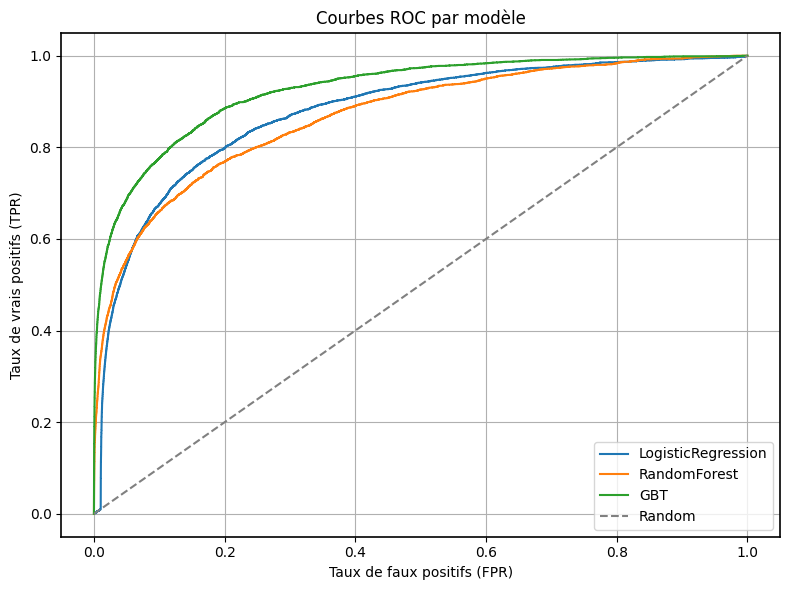

In [11]:
plt.figure(figsize=(8, 6))

for name, preds in predictions.items():
    roc_df = preds.select("proba_1", "isFraud").toPandas()
    roc_df = roc_df.sort_values(by="proba_1", ascending=False)
    roc_df["tp"] = (roc_df["isFraud"] == 1).astype(int)
    roc_df["fp"] = (roc_df["isFraud"] == 0).astype(int)
    roc_df["cum_tp"] = roc_df["tp"].cumsum()
    roc_df["cum_fp"] = roc_df["fp"].cumsum()
    total_pos = roc_df["tp"].sum()
    total_neg = roc_df["fp"].sum()
    roc_df["tpr"] = roc_df["cum_tp"] / total_pos
    roc_df["fpr"] = roc_df["cum_fp"] / total_neg

    plt.plot(roc_df["fpr"], roc_df["tpr"], label=f"{name}")

plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random")
plt.title("Courbes ROC par modèle")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.legend(loc="lower right")
plt.grid(True)
for spine in plt.gca().spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.savefig((PLOTS_DIR / "roc_baselines.png").as_posix(), bbox_inches="tight")
plt.show()


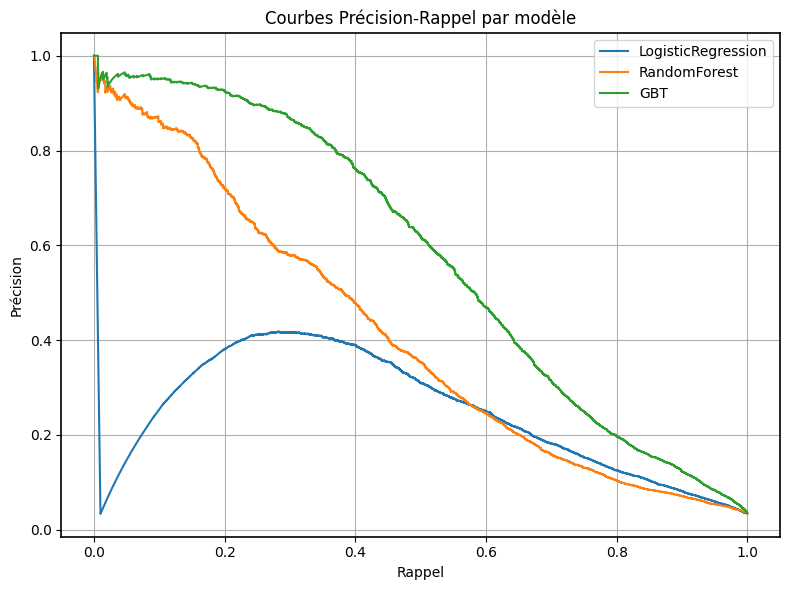

In [12]:
pr_curves = {}

for name, preds in predictions.items():
    df_pd = preds.select("proba_1", "isFraud").toPandas()
    precision, recall, thresholds = precision_recall_curve(df_pd["isFraud"], df_pd["proba_1"])
    pr_curves[name] = (precision, recall, thresholds)

plt.figure(figsize=(8, 6))

for name, (precision, recall, _) in pr_curves.items():
    plt.plot(recall, precision, label=name)

plt.xlabel("Rappel")
plt.ylabel("Précision")
plt.title("Courbes Précision-Rappel par modèle")
plt.legend()
plt.grid(True)
for spine in plt.gca().spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.savefig((PLOTS_DIR / "pr_baselines.png").as_posix(), bbox_inches="tight")
plt.show()


###  7.5 — Analyse guidée des erreurs : FP vs TP vs FN

Objectif : comprendre **où le modèle GBT se trompe** et identifier les profils ayant motivé la création de variables ciblées.

Nous allons comparer trois groupes :
- **False Positives (FP)** : le modèle prédit fraude, mais la transaction est normale
- **True Positives (TP)** : le modèle prédit fraude et la transaction est bien frauduleuse
- **False Negatives (FN)** : le modèle rate une fraude réelle

L'idée n'est pas seulement de regarder les **comptes bruts**, mais aussi la **part de chaque modalité dans chaque groupe**.

Cela nous aidera à :
- détecter des profils sur-représentés dans les **fausses alertes**
- repérer des profils que le modèle **oublie trop souvent**
- justifier les variables ciblées ensuite intégrées dans le pipeline.


In [13]:
gbt_preds = predictions["GBT"]

sample = gbt_preds.sample(fraction=0.2, seed=42).repartition(4)
sample = sample.withColumn("custom_prediction", when(col("proba_1") > 0.8, 1).otherwise(0))

if "log1p_TransactionAmt" in sample.columns:
    sample = sample.withColumn("log1p_TransactionAmt_bucket", spark_round(col("log1p_TransactionAmt"), 1))

false_positives = sample.filter((col("custom_prediction") == 1) & (col("isFraud") == 0))
true_positives  = sample.filter((col("custom_prediction") == 1) & (col("isFraud") == 1))
false_negatives = sample.filter((col("custom_prediction") == 0) & (col("isFraud") == 1))

fp_total = false_positives.count()
tp_total = true_positives.count()
fn_total = false_negatives.count()

print(f"False Positives : {fp_total}")
print(f"True Positives  : {tp_total}")
print(f"False Negatives : {fn_total}")

candidate_variables = [
    "log1p_TransactionAmt_bucket",
    "ProductCD",
    "DeviceType",
    "card4",
    "card6",
    "P_emaildomain",
    "R_emaildomain",
    "P_emaildomain_provider",
    "R_emaildomain_provider",
    "addr1",
    "bank_type",
    "M4",]

variables_a_tester = [var for var in candidate_variables if var in sample.columns]
missing_variables = [var for var in candidate_variables if var not in sample.columns]

print("Variables disponibles pour l'analyse :")
print(variables_a_tester)
if missing_variables:
    print("Variables absentes dans ce notebook :")
    print(missing_variables)

def show_profile(df, var, label, total):
    print(label)
    if total == 0:
        print("Aucun cas dans ce groupe")
        return

    (df.groupBy(var)
       .count()
       .withColumn("share_pct", spark_round(col("count") / lit(total) * 100, 2))
       .orderBy(col("count").desc())
       .show(8, truncate=False))

for var in variables_a_tester:
    print(f"\n====================")
    print(f"Variable : {var}")
    show_profile(false_positives, var, "False Positives", fp_total)

    show_profile(true_positives, var, "True Positives", tp_total)

    show_profile(false_negatives, var, "False Negatives", fn_total)


False Positives : 620
True Positives  : 521
False Negatives : 315
Variables disponibles pour l'analyse :
['log1p_TransactionAmt_bucket', 'ProductCD', 'DeviceType', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'addr1', 'M4']
Variables absentes dans ce notebook :
['P_emaildomain_provider', 'R_emaildomain_provider', 'bank_type']

Variable : log1p_TransactionAmt_bucket
False Positives
+---------------------------+-----+---------+
|log1p_TransactionAmt_bucket|count|share_pct|
+---------------------------+-----+---------+
|4.8                        |46   |7.42     |
|4.1                        |29   |4.68     |
|3.9                        |26   |4.19     |
|5.4                        |26   |4.19     |
|4.4                        |25   |4.03     |
|3.4                        |25   |4.03     |
|4.6                        |25   |4.03     |
|5.1                        |23   |3.71     |
+---------------------------+-----+---------+
only showing top 8 rows

True Positives
+----------------

### Lecture des résultats observés

L’analyse des erreurs au seuil de 0,8 fait apparaître plusieurs différences entre les profils correctement détectés et les fraudes manquées.

#### Type de produit

`ProductCD = W` représente :

- **65,08 %** des faux négatifs ;
- **30,71 %** des vrais positifs ;
- **51,13 %** des faux positifs.

Parmi les fraudes de modalité `W` présentes dans l’échantillon, environ **56,16 %** sont manquées par le modèle. À titre de comparaison, ce taux est d’environ **15,86 %** pour `ProductCD = C`.

#### Informations relatives à l’appareil

`DeviceType = unknown` représente :

- **66,98 %** des faux négatifs ;
- **33,21 %** des vrais positifs ;
- **54,84 %** des faux positifs.

Parmi les fraudes sans type d’appareil renseigné, environ **54,95 %** sont manquées, contre environ **19,15 %** pour les transactions mobiles.

#### Type de carte

Les cartes de débit représentent :

- **59,68 %** des faux négatifs ;
- **47,79 %** des vrais positifs.

Le taux de fraudes manquées dans ce groupe est d’environ **43,02 %**, contre **31,91 %** pour les cartes de crédit.

#### Domaine du destinataire

`R_emaildomain = unknown` représente :

- **67,30 %** des faux négatifs ;
- **33,40 %** des vrais positifs ;
- **53,06 %** des faux positifs.

Environ **54,92 %** des fraudes de ce groupe sont manquées par le modèle, contre environ **20,45 %** lorsque `R_emaildomain = gmail.com`.

#### Variable `M4`

La modalité `M0` représente **42,54 %** des faux négatifs, contre **31,09 %** des vrais positifs. La modalité `M2` représente au contraire **40,88 %** des vrais positifs, mais seulement **14,29 %** des faux négatifs.


#### Conclusion

Cette analyse a motivé la création du pack `FN recovery`, intégré dans le notebook 05. Dans une démarche itérative, les erreurs du modèle baseline ont permis d’identifier des profils récurrents de faux négatifs, puis de les transformer en variables utilisables dans le pipeline final.

Les correspondances principales sont :

- `ProductCD = W` + `DeviceType = unknown` → `is_fn_productW_unknown_device`
- `ProductCD = W` + `R_emaildomain = unknown` → `is_fn_productW_unknown_recipient`
- `card6 = debit` + `DeviceType = unknown` → `is_fn_debit_unknown_device`
- `card6 = debit` + `R_emaildomain = unknown` → `is_fn_debit_unknown_recipient`
- `M4 = M0` + `ProductCD = W` → `is_fn_m4_m0_productW`
- `DeviceType = unknown` + `R_emaildomain = unknown` → `is_fn_unknown_device_unknown_recipient`

L’analyse a aussi motivé des statistiques de risque calculées uniquement sur le train :

- `card1` → `risk_card1_*`
- `ProductCD` + `card6` → `risk_product_card6_*`
- `ProductCD` + `DeviceType` → `risk_product_device_*`
- `DeviceType` + `R_emaildomain` → `risk_device_r_*`
- comportement du montant par carte → `risk_amt_over_card1_mean`, `risk_amt_z_card1`

### Variable complémentaire `is_amount_suspicious`

### Zoom sur `log1p_TransactionAmt`

L’analyse des fausses alertes montre que certains montants reviennent souvent lorsque le modèle prédit une fraude à tort.

Par exemple, plusieurs valeurs de `log1p_TransactionAmt` ressortent fortement chez les **False Positives** :
- `4.77`, soit environ **118** → `1 388` fausses alertes ;
- `4.09`, soit environ **59** → `1 193` fausses alertes ;
- `5.42`, soit environ **226** → `695` fausses alertes.

Ces montants existent aussi dans les vraies fraudes, mais ils correspondent surtout à des montants courants. Le modèle peut donc les interpréter comme suspects alors qu’ils ne suffisent pas seuls à conclure à une fraude.

Nous conservons donc une variable complémentaire `is_amount_suspicious`, qui indique si le montant appartient à une zone souvent observée dans les erreurs du modèle. Cette variable sert de signal additionnel, sans remplacer les autres variables de contexte.

In [14]:
suspicious_values = SUSPICIOUS_VALUES

In [15]:
train_df = add_false_positive_features(train_df)
valid_df = add_false_positive_features(valid_df)
df_final = train_df.unionByName(valid_df)


In [16]:
results_df.to_csv((TABLES_DIR / "baseline_results.csv").as_posix(), index=False)
train_df.write.mode("overwrite").parquet((STAGE_DATA_DIR / "train_features_enriched_train_split.parquet").as_posix())
valid_df.write.mode("overwrite").parquet((STAGE_DATA_DIR / "train_features_enriched_valid_split.parquet").as_posix())
df_final.write.mode("overwrite").parquet((STAGE_DATA_DIR / "train_features_enriched.parquet").as_posix())

save_json(
    METRICS_DIR / "baseline_split_summary.json",
    {
        "train_rows": int(train_df.count()),
        "valid_rows": int(valid_df.count()),
        "global_rows": int(df_final.count()),
        "false_positives": int(false_positives.count()),
        "true_positives": int(true_positives.count()),
        "suspicious_values": suspicious_values,
        "split_seed": int(split_metadata["split_seed"]),
        "split_origin": "05_feature_engineering",
    },)

for model_name, params in model_param_specs.items():
    subset = results_df[results_df["Model"] == model_name]
    with mlflow.start_run(run_name=model_name, nested=True):
        mlflow.set_tag("stage", STAGE_NAME)
        mlflow.log_params(params)
        for _, row in subset.iterrows():
            prefix = row["Dataset"]
            mlflow.log_metric(f"{prefix}_auc", float(row["AUC"]))
            mlflow.log_metric(f"{prefix}_f1", float(row["F1"]))
            mlflow.log_metric(f"{prefix}_accuracy", float(row["Accuracy"]))
            mlflow.log_metric(f"{prefix}_precision", float(row["Precision"]))
            mlflow.log_metric(f"{prefix}_recall", float(row["Recall"]))

valid_rows = results_df[results_df["Dataset"] == "valid"]
best_valid = valid_rows.sort_values("F1", ascending=False).iloc[0]
mlflow.log_metrics(
    {
        "best_valid_f1": float(best_valid["F1"]),
        "best_valid_auc": float(best_valid["AUC"]),
    })
mlflow.log_param("baseline_threshold", 0.4)
mlflow.log_param("split_origin", "05_feature_engineering_no_leakage")

mlflow.log_artifacts(STAGE_ARTIFACTS_DIR.as_posix(), artifact_path=STAGE_NAME)
mlflow.end_run()
print(f"Jeu enrichi sauvegardé dans {STAGE_DATA_DIR}")


Jeu enrichi sauvegardé dans C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\06_modeling_baselines\data
